# Data Augmentation in Deep Learning (CNN)

---

## 1. Executive Summary

**Data Augmentation** is a critical technique in Deep Learning used to artificially expand the size and diversity of a training dataset by applying randomized, domain-realistic geometric and photometric transformations to existing images. 

### Primary Objectives & Benefits
1. **Mitigates Overfitting:** Prevents neural networks from memorizing spurious patterns (e.g., orientation or positional biases) by forcing them to learn invariant feature representations.
2. **Solves Small Dataset / High Data Acquisition Costs:** Essential in specialized domains (e.g., medical imaging) where collecting real samples is expensive or constrained.
3. **Improves Model Generalization:** Enhances test accuracy on unseen data by exposing the model to varied lighting, shifts, and orientations during training.

---

## 2. Core Concepts & Common Transformations

Data Augmentation generates synthetic versions of input images dynamically during training.
* **Rotation (`rotation_range`):** Rotates images randomly within a specified degree angle.
* **Horizontal Flip (`horizontal_flip`):** Flips images horizontally. *(Note: Avoid Vertical Flips for natural objects like animals/cats where inverted orientations are unrealistic).*
* **Width/Height Shift (`width_shift_range`, `height_shift_range`):** Translates images horizontally or vertically to teach location invariance.
* **Shear (`shear_range`):** Distorts image angles along an axis.
* **Zoom (`zoom_range`):** Randomly zooms inside or outside the image frame.
* **Fill Mode (`fill_mode`):** Fills missing boundary pixels created by shifts/rotations (e.g., `nearest`, `reflect`, `constant`).

---

## 3. Important Design Rules & Best Practices

1. **Augment ONLY Training Data:** Never apply geometric or photometric transformations to `validation` or `test` datasets. Validation data should only undergo standard preprocessing (e.g., rescaling/normalization) to maintain ground-truth integrity.
2. **Dynamic Generation:** Transformations are typically applied dynamically in VRAM per mini-batch during training, avoiding the need to store millions of generated images on disk.

In [2]:
from keras.preprocessing import image 
# from keras.preprocessing.image import ImageDataGenerator 
from tensorflow.keras.preprocessing.image import ImageDataGenerator 
import matplotlib.pyplot as plt 

In [4]:
img = image.load_img('train/cat.18.jpg' , target_size=(200,200))

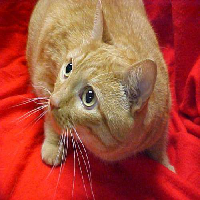

In [6]:
img

In [8]:
type(img)

# right now its in a Python Image Lib , we'll convert this into numpy array in next cells

PIL.Image.Image

In [10]:
img = image.img_to_array(img)

type(img)

numpy.ndarray

In [11]:
img.shape

(200, 200, 3)

In [13]:
# Data Augmentation 
datagen = ImageDataGenerator(
    rotation_range=30, 
    shear_range=0.2, 
    zoom_range=0.2, 
    horizontal_flip=True , 
    width_shift_range=0.2, 
    height_shift_range=0.2, 
    fill_mode='constant'
)

In [14]:
# Convert and prepare input data 
input_batch = img.reshape(1,200,200,3)

In [17]:
i = 0 

# output batch 
for output in datagen.flow(input_batch, batch_size=1, save_to_dir='aug'): 

    i = i + 1 

    if i == 10:
        break 